In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("gustavomodelli/forest-fires-in-brazil")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\RonitJadhav\.cache\kagglehub\datasets\gustavomodelli\forest-fires-in-brazil\versions\1


In [3]:
import os
df = pd.read_csv(os.path.join(path, "amazon.csv"), encoding="latin1")

#### 1. Display Top 5 Rows of The Dataset


In [4]:
df.head(5)

,year,state,month,number,date
0,1998,Acre,Janeiro,0.0,1998-01-01
1,1999,Acre,Janeiro,0.0,1999-01-01
2,2000,Acre,Janeiro,0.0,2000-01-01
3,2001,Acre,Janeiro,0.0,2001-01-01
4,2002,Acre,Janeiro,0.0,2002-01-01


#### 2. Check Last 5 Rows


In [5]:
df.tail(5)

,year,state,month,number,date
6449,2012,Tocantins,Dezembro,128.0,2012-01-01
6450,2013,Tocantins,Dezembro,85.0,2013-01-01
6451,2014,Tocantins,Dezembro,223.0,2014-01-01
6452,2015,Tocantins,Dezembro,373.0,2015-01-01
6453,2016,Tocantins,Dezembro,119.0,2016-01-01


#### 3. Find Shape of Our Dataset (Number of Rows And Number of Columns)

In [6]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

Rows: 6454
Columns: 5


#### 4. Getting Information About Our Dataset Like Total Number Rows, Total Number of Columns, Datatypes of Each Column And Memory Requirement


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6454 entries, 0 to 6453
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   year    6454 non-null   int64  
 1   state   6454 non-null   object 
 2   month   6454 non-null   object 
 3   number  6454 non-null   float64
 4   date    6454 non-null   object 
dtypes: float64(1), int64(1), object(3)
memory usage: 252.2+ KB


#### 5. Check For Duplicate Data and Drop Them


In [8]:
df.isnull().count()

year      6454
state     6454
month     6454
number    6454
date      6454
dtype: int64

In [9]:
df.isna().sum()

year      0
state     0
month     0
number    0
date      0
dtype: int64

#### 8. Rename Month Names To English


In [10]:
month_mapping = {
    'Janeiro': 'January',
    'Fevereiro': 'February',
    'Março': 'March',
    'Abril': 'April',
    'Maio': 'May',
    'Junho': 'June',
    'Julho': 'July',
    'Agosto': 'August',
    'Setembro': 'September',
    'Outubro': 'October',
    'Novembro': 'November',
    'Dezembro': 'December'
}

In [11]:
df['month'] = df['month'].map(month_mapping)

In [12]:
df['month'].unique()

array(['January', 'February', 'March', 'April', 'May', 'June', 'July',
       'August', 'September', 'October', 'November', 'December'],
      dtype=object)

#### 9. Total Number of Fires Registered

In [13]:
df['number'].sum()

698924.073

#### 10. In Which Month Maximum Number of Forest Fires Were Reported?


In [14]:
df1 = df.groupby('month')['number'].count()

In [15]:
df1.sort_values(ascending=False)

month
January      541
April        540
August       540
February     540
July         540
June         540
March        540
May          540
November     540
October      540
September    540
December     513
Name: number, dtype: int64

#### 11. In Which Year Maximum Number of Forest Fires Was Reported?


In [16]:
df1 = df.groupby('year')['number'].count()
df1.sort_values(ascending=False).head(1)

year
1998    324
Name: number, dtype: int64

#### 12. In Which State Maximum Number of Forest Fires Was Reported?


In [17]:
df1 = df.groupby('state')['number'].count()
df1.sort_values(ascending=False).head(5)

state
Rio            717
Mato Grosso    478
Paraiba        478
Alagoas        240
Acre           239
Name: number, dtype: int64

#### 13. Find Total Number of Fires Were Reported In Amazonas


In [18]:
df1 = df['state'].value_counts()

df1['Amazonas']

239

#### 14. Display Number of Fires Were Reported In Amazonas (Year-Wise)


In [19]:
amazonas = df[df['state'] == 'Amazonas']

amazonas.groupby('year').size()


year
1998    12
1999    12
2000    12
2001    12
2002    12
2003    12
2004    12
2005    12
2006    12
2007    12
2008    12
2009    12
2010    12
2011    12
2012    12
2013    12
2014    12
2015    12
2016    12
2017    11
dtype: int64

#### 15. Display Number of Fires Were Reported In Amazonas (Day-Wise)


In [29]:
df['number'].value_counts()

number
0.000      617
1.000      237
2.000      174
3.000      143
4.000      115
          ... 
325.000      1
655.000      1
705.000      1
1.085        1
623.000      1
Name: count, Length: 1479, dtype: int64

In [28]:
amazonas = df[df['state'] == 'amazonas']

results = amazonas.groupby('date')['number'].sum()

print(results)

Series([], Name: number, dtype: float64)


#### 16. Find Total Number of Fires  Were Reported In 2015 And Visualize Data Based on Each ‘Month’


In [50]:
fire = df[df['year'] == 2015].groupby('month')['number'].sum().reset_index()

fire

,month,number
0,April,2573.000
1,August,4363.125
2,December,4088.522
3,February,2309.000
4,January,4635.000
5,July,4364.392
6,June,3260.552
7,March,2202.000
8,May,2384.000
9,November,4034.518


<Axes: xlabel='month', ylabel='number'>

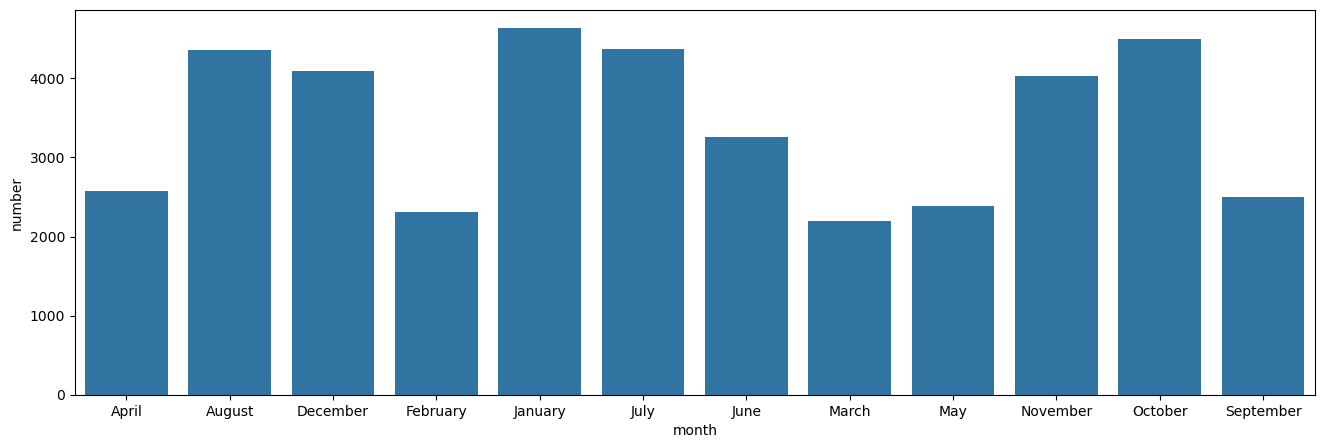

In [55]:
import seaborn as sns

plt.figure(figsize=(16,5))
sns.barplot(x='month',y = 'number',data=fire)